Performing EDA on dataset

In [13]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='str')
72134
Raw Counts:
label
1    37106
0    35028
Name: count, dtype: int64

Percentages:
label
1    51.44
0    48.56
Name: proportion, dtype: float64


C:\Users\Sagar Patle\AppData\Local\Temp\ipykernel_13384\3273282730.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df, palette='Set2')


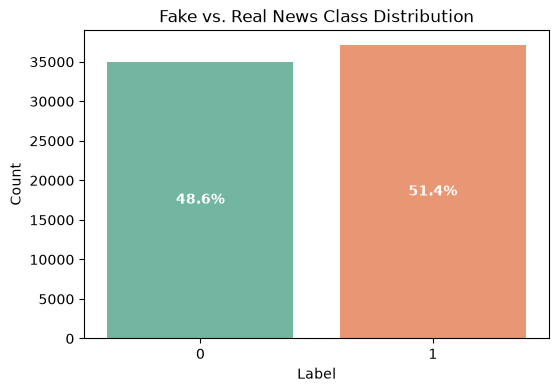

In [14]:
import pandas as pd

# Load the dataset
df = pd.read_csv('C:/Users/Sagar Patle/Desktop/FakeNewsClasification/data/WELFake_Dataset.csv')

# Check basic info
print(df.columns)
print(len(df))

#checking if the dataset is imbalanced or not
# Raw counts of each class
counts = df['label'].value_counts()
print("Raw Counts:")
print(counts)

print("\nPercentages:")
# Normalized values (percentages)
percentages = df['label'].value_counts(normalize=True) * 100
print(percentages.round(2))

#Visualising the distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df, palette='Set2')

# Annotate each bar with its exact percentage
total = len(df['label'])
for p in ax.patches:
    height = p.get_height()
    percentage = f"{100 * height / total:.1f}%"
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.title('Fake vs. Real News Class Distribution')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

In [18]:
#Checking for Missing Data
# Returns the total count of missing (NaN/Null) rows in the 'text' column
missing_count = df['text'].isnull().sum()

print(f"Missing values in 'text': {missing_count}")

# Returns the percentage of missing values (multiplied by 100 for readability)
missing_percentage = df['text'].isnull().mean() * 100

print(f"Percentage missing in 'text': {missing_percentage:.2f}%")

# Returns the total count of missing (NaN/Null) rows in the 'title' column
missing_count = df['title'].isnull().sum()

print(f"Missing values in 'title': {missing_count}")

# Returns the percentage of missing values (multiplied by 100 for readability)
missing_percentage = df['title'].isnull().mean() * 100

print(f"Percentage missing in 'title': {missing_percentage:.2f}%")


Missing values in 'text': 39
Percentage missing in 'text': 0.05%
Missing values in 'title': 558
Percentage missing in 'title': 0.77%


In [19]:
#Finding the distribution of fake news and real news for missing values in the dataset
# 1. Isolate the rows where the 'text' column is NaN/Null
missing_text_rows = df[df['text'].isnull()]

# 2. Count how many of these missing rows belong to each label
missing_distribution = missing_text_rows['label'].value_counts()
print("Raw Counts of missing text by class:")
print(missing_distribution)

# 3. View it as a percentage
missing_percentages = missing_text_rows['label'].value_counts(normalize=True) * 100
print("\nPercentage Breakdown:")
print(missing_percentages.round(2))

Raw Counts of missing text by class:
label
1    39
Name: count, dtype: int64

Percentage Breakdown:
label
1    100.0
Name: proportion, dtype: float64


The above insight shows only 0.05% of the whole data for text column is missing and removing them does not add any significant difference to the distribution of fake news and real news in the dataset.So it's safe to remove those missing values and for title column it's safe to leave missing values intact because at the end we are going to concatenate both the columns into single one so it's easy for classifier to learn the pattern in the data.

In [21]:
#concating title and text column to create one new column full_text 
df['title'] = df['title'].fillna('')
# Add a space between title and text so words don't mash together
df['full_text'] = df['title'] + " " + df['text']

In [25]:
# Creating new dataset with only full_text and labels columns
#  Subset the DataFrame to keep ONLY the two columns you need
df_clean = df[['full_text', 'label']]

# Export to a new CSV file
# index=False prevents pandas from adding an extra column of row numbers
df_clean.to_csv('C:/Users/Sagar Patle/Desktop/FakeNewsClasification/data/cleaned_fake_news_data.csv', index=False)

print("Cleaned CSV successfully saved!")

Cleaned CSV successfully saved!
